# Laboratorium 6 — pooling i pełna CNN

## 1. Konfiguracja

In [1]:
import json
import random
import time
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

CFG = dict(epochs=6, lr=0.001, batch_size=128, seed=42)
DATASET = "CIFAR10"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Urządzenie", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))
print(CFG)

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_all(CFG["seed"])


def save_progress(results):
    Path("wyniki_lab06.json").write_text(json.dumps(results, indent=2))

def show_plot(fig):
    plt.show()


PyTorch 2.7.1+cpu | torchvision 0.22.1+cpu
Urządzenie cpu
{'epochs': 6, 'lr': 0.001, 'batch_size': 128, 'seed': 42}


## 2. Dane

Przetworzone tensory są buforowane w RAM, aby uniknąć powtarzanej normalizacji. To te same 50 000 obrazów treningowych i 10 000 testowych. Bez augmentacji i bez podzbiorów.

In [ ]:
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914,0.4822,0.4465), (0.2470,0.2435,0.2616)),
])
train_ds = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=tf)
test_ds = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf)
def cache_dataset(dataset):
    images = torch.from_numpy(dataset.data).permute(0,3,1,2).float().div_(255)
    mean = torch.tensor((0.4914,0.4822,0.4465)).view(1,3,1,1)
    std = torch.tensor((0.2470,0.2435,0.2616)).view(1,3,1,1)
    images.sub_(mean).div_(std)
    return TensorDataset(images, torch.tensor(dataset.targets, dtype=torch.long))

train_ds = cache_dataset(train_ds)
test_ds = cache_dataset(test_ds)
print("Trening", len(train_ds), "| test", len(test_ds))

def loader(dataset, shuffle=False):
    return DataLoader(
        dataset, batch_size=CFG["batch_size"] if shuffle else 256,
        shuffle=shuffle, num_workers=0,
        generator=torch.Generator().manual_seed(CFG["seed"]),
        pin_memory=device.type == "cuda",
    )

Trening 50000 | test 10000


## 3. Wspólna architektura i trzy warianty redukcji

In [ ]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max"):
        super().__init__()
        if pool not in ("max", "avg", "stride"):
            raise ValueError(pool)

        def block(cin, cout):
            layers = [
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout), nn.ReLU(),
            ]
            if pool == "max":
                layers.append(nn.MaxPool2d(2, stride=2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2, stride=2))
            else:
                layers.extend([
                    nn.Conv2d(cout, cout, 3, stride=2, padding=1),
                    nn.BatchNorm2d(cout), nn.ReLU(),
                ])
            return nn.Sequential(*layers)

        self.features = nn.Sequential(block(3,32), block(32,64))
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64,n_classes)
        )

    def forward(self, x):
        return self.head(self.features(x))

def count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

seed_all(CFG["seed"])
common_state = CNN(pool="max").state_dict()
models = {}
for variant in ("max", "avg", "stride"):
    seed_all(CFG["seed"])
    model = CNN(pool=variant)
    state = model.state_dict()
    for name in common_state:
        if name in state and state[name].shape == common_state[name].shape:
            state[name] = common_state[name].clone()
    model.load_state_dict(state)
    model.eval()
    with torch.inference_mode():
        shape = list(model.features(torch.zeros(1,3,32,32)).shape[1:])
        assert model(torch.zeros(1,3,32,32)).shape == (1,10)
    models[variant] = model
    print(variant, "| parametry", count(model), "| przed GAP", shape)


max | parametry 20234 | przed GAP [64, 8, 8]
avg | parametry 20234 | przed GAP [64, 8, 8]
stride | parametry 66602 | przed GAP [64, 8, 8]


## 4. Trening i pomiar accuracy

In [ ]:
@torch.inference_mode()
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    for xb,yb in dl:
        logits = model(xb.to(device=device, memory_format=torch.channels_last))
        correct += (logits.argmax(1) == yb.to(device)).sum().item()
        total += yb.numel()
    return correct / total

results = {}
for variant, model in models.items():
    seed_all(CFG["seed"])
    train_dl = loader(train_ds, shuffle=True)
    train_eval_dl = loader(train_ds)
    test_dl = loader(test_ds)
    model = model.to(device=device, memory_format=torch.channels_last)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    criterion = nn.CrossEntropyLoss()
    hist = dict(train_acc=[], test_acc=[])
    start = time.perf_counter()
    print("\n==", variant, "==", flush=True)
    for epoch in range(1, CFG["epochs"]+1):
        model.train()
        for xb,yb in train_dl:
            xb,yb = xb.to(device=device, memory_format=torch.channels_last),yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb),yb)
            loss.backward()
            opt.step()
        tr = evaluate(model, train_eval_dl)
        te = evaluate(model, test_dl)
        hist["train_acc"].append(tr)
        hist["test_acc"].append(te)
        print(f"epoka {epoch} | trening {tr:.4%} | test {te:.4%}", flush=True)
    if device.type == "cuda":
        torch.cuda.synchronize()
    model.eval()
    with torch.inference_mode():
        shape = list(model.features(torch.zeros(1,3,32,32,device=device)).shape[1:])
    results[variant] = dict(
        params=count(model), shape=shape, hist=hist,
        seconds_with_eval=time.perf_counter()-start,
    )
    save_progress(results)



== max ==
epoka 1 | trening 41.9060% | test 41.8000%
epoka 2 | trening 46.8520% | test 46.1600%
epoka 3 | trening 47.9220% | test 46.8900%
epoka 4 | trening 54.2820% | test 53.4400%
epoka 5 | trening 54.0220% | test 52.9800%
epoka 6 | trening 54.7660% | test 53.9500%

== avg ==
epoka 1 | trening 42.4480% | test 42.2800%
epoka 2 | trening 45.9160% | test 45.3000%
epoka 3 | trening 48.8600% | test 48.2700%
epoka 4 | trening 53.4400% | test 52.7100%
epoka 5 | trening 52.1380% | test 51.2800%
epoka 6 | trening 52.9020% | test 52.4300%

== stride ==
epoka 1 | trening 54.6200% | test 54.3800%
epoka 2 | trening 53.2120% | test 52.6400%
epoka 3 | trening 62.9460% | test 60.8700%
epoka 4 | trening 69.2980% | test 67.6700%
epoka 5 | trening 64.2260% | test 62.5400%
epoka 6 | trening 69.7440% | test 66.3600%


## 5. Wyniki po ostatniej epoce

In [5]:
labels = dict(max="Max pooling 2×2", avg="Average pooling 2×2", stride="Splot 3×3 stride 2")
table = [
    "| Wariant | Parametry | Mapa przed GAP [C,H,W] | Acc. trening | Acc. test | Przerwa [p.p.] |",
    "|---|---:|---|---:|---:|---:|",
]
for variant,r in results.items():
    tr,te = r["hist"]["train_acc"][-1],r["hist"]["test_acc"][-1]
    table.append(f"| {labels[variant]} | {r['params']:,} | {r['shape']} | {tr:.2%} | {te:.2%} | {100*(tr-te):+.2f} |")
display(Markdown("\n".join(table)))


| Wariant | Parametry | Mapa [C,H,W] | Acc. trening | Acc. test | Przerwa [p.p.] |
|---|---:|---|---:|---:|---:|
| max | 20234 | [64, 8, 8] | 54.77% | 53.95% | +0.82 |
| avg | 20234 | [64, 8, 8] | 52.90% | 52.43% | +0.47 |
| stride | 66602 | [64, 8, 8] | 69.74% | 66.36% | +3.38 |

## 6. Krzywe accuracy

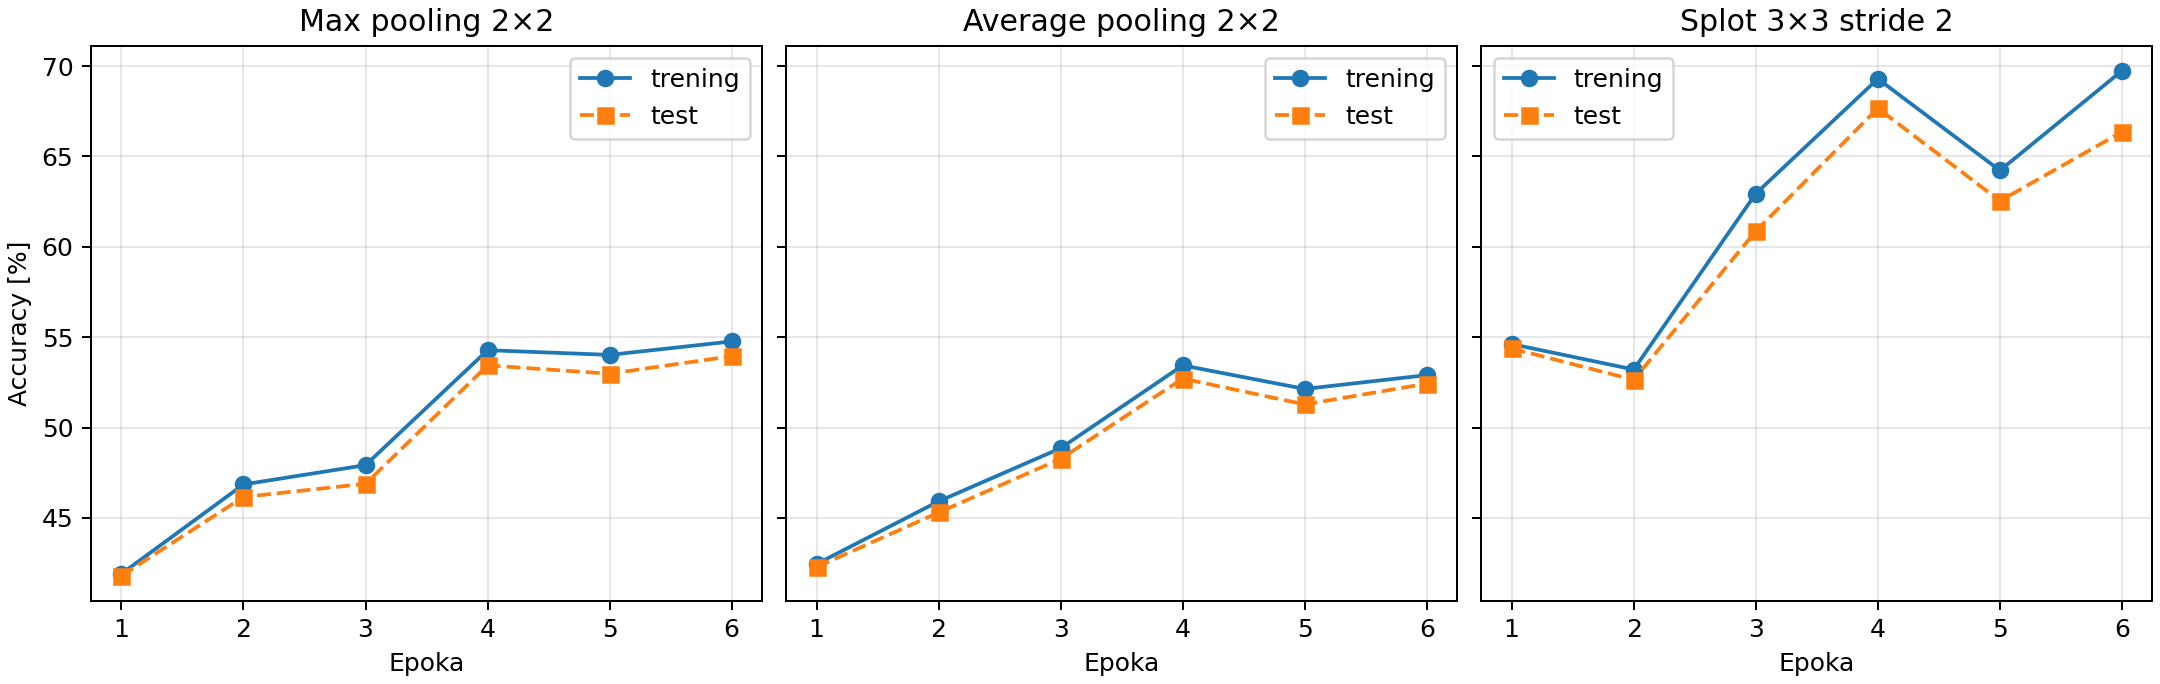

In [6]:
fig, axes = plt.subplots(1,3,figsize=(12,3.8),sharey=True,layout="constrained")
for ax,(variant,r) in zip(axes,results.items()):
    ep = range(1,CFG["epochs"]+1)
    ax.plot(ep,np.array(r["hist"]["train_acc"])*100,"o-",label="trening")
    ax.plot(ep,np.array(r["hist"]["test_acc"])*100,"s--",label="test")
    ax.set(title=labels[variant],xlabel="Epoka",xticks=list(ep))
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Accuracy [%]")
show_plot(fig)
